# ML Zoomcamp 2026 - Homework 4: Evaluation Metrics for Classification

Same lead-scoring dataset as homework 3 (target: `converted`). This time the focus is on **how we measure** a classifier: ROC AUC, precision, recall, F1 and cross-validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

%matplotlib inline

## Data preparation

In [2]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)

categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']

df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [3]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df.isnull().sum().sum()

np.int64(0)

## Split

Exact calls from the homework (note: `random_state=1` this time, not 42).

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['converted'].values
y_val = df_val['converted'].values

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Q1. ROC AUC as feature importance

AUC is the probability that a random positive example gets a higher score than a random negative one. 0.5 = random guessing, 1.0 = perfect ranking. Here each numerical column is used directly as the score. If AUC < 0.5 the column is negatively related to the target, so we negate it.

In [5]:
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
        print(f'{col:28s} {auc:.4f}  (inverted)')
    else:
        print(f'{col:28s} {auc:.4f}')

number_of_courses_viewed     0.7230
annual_income                0.6082
interaction_count            0.7649
lead_score                   0.7882


## Q2. Train the model

One-hot encoding with `DictVectorizer` (fitted on train only), then logistic regression. For AUC we need **probabilities** (`predict_proba`), not hard 0/1 predictions.

In [6]:
features = categorical + numerical


def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_tr, y_tr)
    return dv, model


def predict(df_, dv, model):
    X = dv.transform(df_[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

In [7]:
dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)

round(roc_auc_score(y_val, y_pred), 3)

0.732

## Q3. Precision and recall

For each threshold `t`, a lead is predicted as converted if its probability is `>= t`.

- **Precision** = TP / (TP + FP): of the leads we flagged, how many really converted.
- **Recall** = TP / (TP + FN): of the leads that really converted, how many we flagged.

At very high thresholds nothing is predicted positive, so precision is 0/0; we set it to 0 there.

In [8]:
thresholds = np.linspace(0, 1, 101)
actual_pos = (y_val == 1)
actual_neg = (y_val == 0)

rows = []
for t in thresholds:
    pred_pos = (y_pred >= t)
    pred_neg = (y_pred < t)

    tp = (pred_pos & actual_pos).sum()
    fp = (pred_pos & actual_neg).sum()
    fn = (pred_neg & actual_pos).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append((t, tp, fp, fn, precision, recall))

df_scores = pd.DataFrame(rows, columns=['threshold', 'tp', 'fp', 'fn', 'precision', 'recall'])
df_scores[::10]

,threshold,tp,fp,fn,precision,recall
0,0.0,586,414,0,0.586000,1.000000
10,0.1,586,414,0,0.586000,1.000000
20,0.2,586,414,0,0.586000,1.000000
30,0.3,586,403,0,0.592518,1.000000
40,0.4,573,362,13,0.612834,0.977816
50,0.5,531,294,55,0.643636,0.906143
60,0.6,457,190,129,0.706337,0.779863
70,0.7,311,82,275,0.791349,0.530717
80,0.8,139,23,447,0.858025,0.237201
90,0.9,19,1,567,0.950000,0.032423


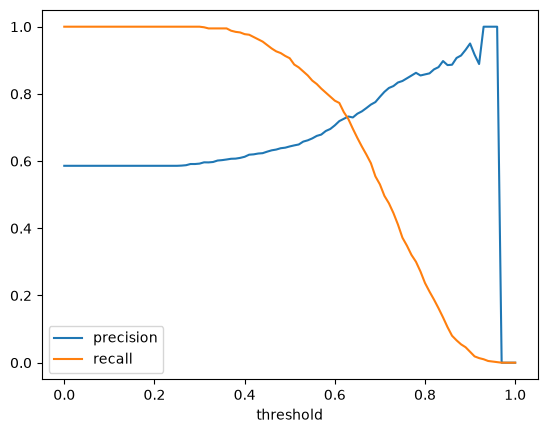

In [9]:
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

In [10]:
# Ignore thresholds where both are zero, then take the smallest |precision - recall|
valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
valid.sort_values('diff').head(5)

,threshold,tp,fp,fn,precision,recall,diff
63,0.63,425,155,161,0.732759,0.725256,0.007503
62,0.62,437,165,149,0.725914,0.745734,0.019820
64,0.64,408,151,178,0.729875,0.696246,0.033629
61,0.61,453,177,133,0.719048,0.773038,0.053990
65,0.65,392,137,194,0.741021,0.668942,0.072079


## Q4. F1 score

F1 is the harmonic mean of precision and recall: it is high only when **both** are high.

In [11]:
p = df_scores.precision
r = df_scores.recall
df_scores['f1'] = np.where((p + r) > 0, 2 * p * r / (p + r), 0.0)

df_scores.sort_values('f1', ascending=False).head(5)

,threshold,tp,fp,fn,precision,recall,f1
41,0.41,572,352,14,0.619048,0.976109,0.757616
42,0.42,568,348,18,0.620087,0.969283,0.756325
43,0.43,564,342,22,0.622517,0.962457,0.756032
45,0.45,554,328,32,0.628118,0.945392,0.754768
44,0.44,560,338,26,0.623608,0.955631,0.754717


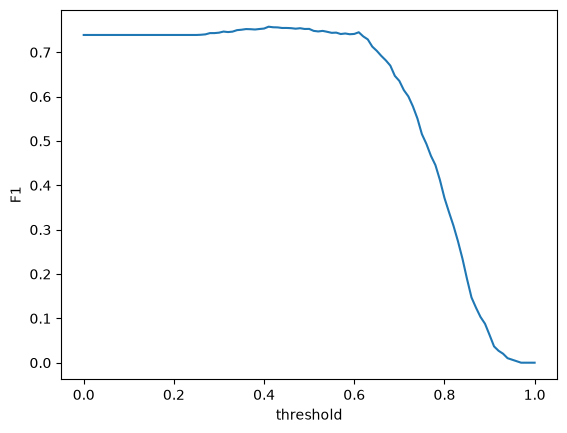

In [12]:
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold')
plt.ylabel('F1')
plt.show()

## Q5. 5-fold cross-validation

Instead of a single train/validation split, `df_full_train` is split into 5 folds. Each fold takes a turn as validation while the other 4 are used for training. The std of the 5 AUCs tells us how stable the model is.

In [13]:
def cross_validate(C=1.0):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        y_tr = df_tr['converted'].values
        y_va = df_va['converted'].values

        dv, model = train(df_tr, y_tr, C=C)
        scores.append(roc_auc_score(y_va, predict(df_va, dv, model)))
    return scores

In [14]:
scores = cross_validate(C=1.0)
print([round(s, 3) for s in scores])
print('mean:', round(np.mean(scores), 3))
print('std: ', round(np.std(scores), 3))

[0.731, 0.73, 0.736, 0.741, 0.721]
mean: 0.732
std:  0.007


## Q6. Tuning `C` with cross-validation

Smaller `C` = stronger regularization. Pick the best mean AUC; on ties, lowest std, then smallest `C`.

In [15]:
results = []
for C in [0.000001, 0.001, 1]:
    s = cross_validate(C=C)
    results.append((C, round(np.mean(s), 3), round(np.std(s), 3)))
    print(f'C={C:<10} mean={results[-1][1]}  std={results[-1][2]}')

C=1e-06      mean=0.617  std=0.019
C=0.001      mean=0.749  std=0.01


C=1          mean=0.732  std=0.007


In [16]:
best = sorted(results, key=lambda x: (-x[1], x[2], x[0]))[0]
best

(0.001, np.float64(0.749), np.float64(0.01))